In [5]:
# Updating package with new changes
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

Initial State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Unassigned
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Unassigned
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Unassigned
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Truck b at (1, 0, 0)

Final State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck a at (0, 5, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Truck a at (0, 5, 1)
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Truck a at (0, 7, 1)
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Truck a at (0, 0, 0)
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Truck b at (1, 0, 0)

Final Objective Value: 250
Runtime: 1.9341908319997856
Iterations: 5


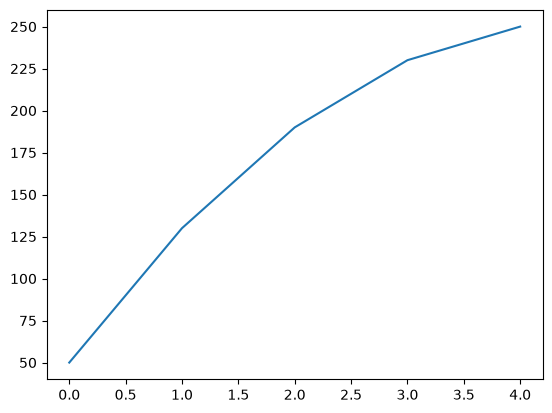

In [13]:
# Trying Steepest Ascent Hill Climbing
from src.engine import *
from src.solvers.hill_climbing import SteepestAscent
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = [
   # Package(id, width, length, height, value, weight, is_fragile, eta) 
   Package("A", 3, 4, 1, 60, 5, False, 3), 
   Package("B", 2, 2, 2, 40, 3, True, 1),
   Package("C", 1, 1, 1, 20, 1, False, 2),
   Package("D", 4, 5, 2, 80, 7, True, 4),
   Package("E", 2, 3, 1, 50, 4, False, 5)
]
# Truck(id, width, length, height, max_capacity)
trucks = [Truck("a", 10, 20, 5, 25), Truck("b", 8, 15, 4, 30)]

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Steepest Ascent Hill Climbing
solver_steepest_ascent = SteepestAscent(obj, max_iterations = 100)
results_steepest_ascent = solver_steepest_ascent.solve(initial_state)

# Getting the results
print("Final State:", results_steepest_ascent.final_state) # Output: Final State
print("Final Objective Value:", results_steepest_ascent.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_steepest_ascent.runtime) # Output: Runtime
print("Iterations:", results_steepest_ascent.total_iterations) # Output: Iterations
plt.plot(results_steepest_ascent.objective_history) # Output: Plot of Objective Value over Iterations

In [ ]:
# Trying Sideways Move Hill Climbing
from src.engine import *
from src.solvers.hill_climbing import SidewaysMove
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = [
   # Package(id, width, length, height, value, weight, is_fragile, eta) 
   Package("A", 3, 4, 1, 60, 5, False, 3), 
   Package("B", 2, 2, 2, 40, 3, True, 1),
   Package("C", 1, 1, 1, 20, 1, False, 2),
   Package("D", 4, 5, 2, 80, 7, True, 4),
   Package("E", 2, 3, 1, 50, 4, False, 5)
]
# Truck(id, width, length, height, max_capacity)
trucks = [Truck("a", 10, 20, 5, 25), Truck("b", 8, 15, 4, 30)]

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_sideways_move = SidewaysMove(obj, max_iterations = 100)
results_sideways_move = solver_sideways_move.solve(initial_state)

# Getting the results
print("Final State:", results_sideways_move.final_state) # Output: Final State
print("Final Objective Value:", results_sideways_move.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_sideways_move.runtime) # Output: Runtime
print("Iterations:", results_sideways_move.total_iterations) # Output: Iterations
# [placeholder] add number of sideways move
plt.plot(results_sideways_move.objective_history) # Output: Plot of Objective Value over Iterations